In [1]:
from pathlib import Path
import joblib

import traceback
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import shap
from lime.lime_tabular import LimeTabularExplainer

model_path = Path(
    r"C:\Users\cgqua\Downloads\KevsAndEricka\mlops_deployment\ai_engineering_portfolio\projects\explainable-iris\src\models\iris_random_forest.joblib"
)

model = joblib.load(model_path)

In [2]:
iris = load_iris()

X = iris.data
y = iris.target

feature_names = iris.feature_names
class_names = list(iris.target_names)

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


FEATURE IMPORTANCE

Which measurements influence the model most?
          Feature Importance
 petal width (cm)     0.4372
petal length (cm)     0.4315
sepal length (cm)     0.1163
 sepal width (cm)     0.0150


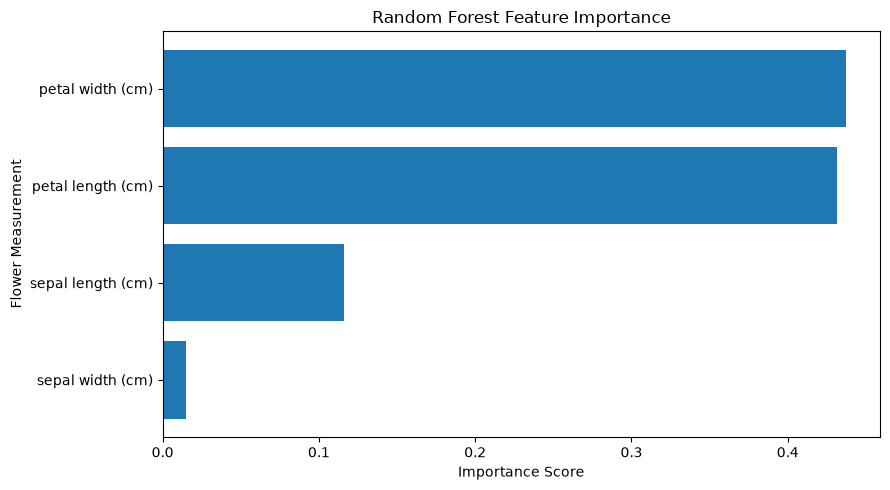

In [4]:
print("\n" + "=" * 65)
print("FEATURE IMPORTANCE")
print("=" * 65)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": model.feature_importances_
}).sort_values(
    by = "Importance",
    ascending=False
)

print("\nWhich measurements influence the model most?")

print(importance_df.to_string(
    index = False,
    formatters={"Importance": "{:.4f}".format}
))

#First Graph

plt.figure(figsize=(9,5))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Flower Measurement")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [5]:
#Predict An Example Flower

sample_index = 0
sample = X_test[sample_index].reshape(1,-1)
actual_species = class_names[y_test[sample_index]]
predicted_class = int(model.predict(sample)[0])
predicted_species = class_names[predicted_class]

probabilities = model.predict_proba(sample)[0]

In [6]:
print("\n" + "=" * 65)
print("SAMPLE PREDICTION")
print("=" * 65)

print("\nFlower Measurements:")

for name, value in zip(feature_names, sample[0]):
    print(f"{name}: {value:.2f} cm")

print(f"\nActual Species: {actual_species}")
print(f"Predicted Species: {predicted_species}")

print("\nPrediction Probabilites:")

for species, probability in zip(class_names, probabilities):
    print(f"{species}: {probability:.2%}")


SAMPLE PREDICTION

Flower Measurements:
sepal length (cm): 4.40 cm
sepal width (cm): 3.00 cm
petal length (cm): 1.30 cm
petal width (cm): 0.20 cm

Actual Species: setosa
Predicted Species: setosa

Prediction Probabilites:
setosa: 100.00%
versicolor: 0.00%
virginica: 0.00%



SHAP EXPLAINABILITY

Calculating SHAP Values

Global SHAP feature importance:
          Feature Mean Absolute SHAP Value
 petal width (cm)                  0.20224
petal length (cm)                  0.19886
sepal length (cm)                  0.04276
 sepal width (cm)                  0.00482


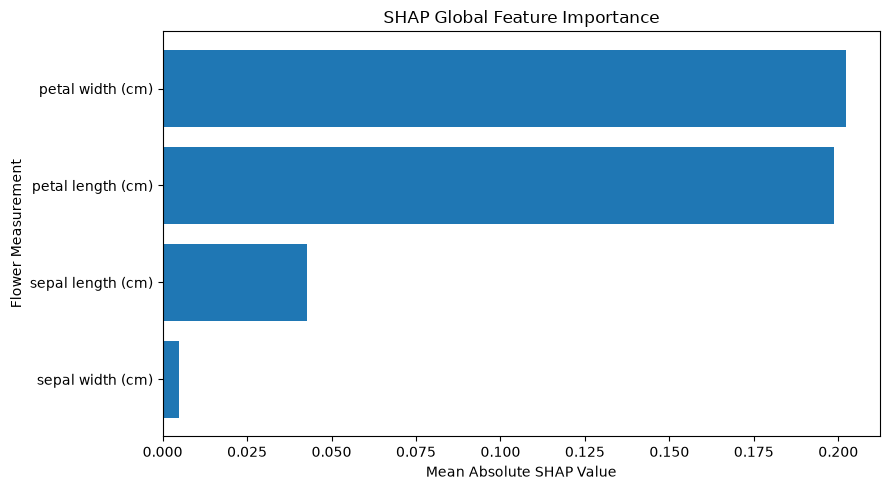


 SHAP Explanation for the sample prediction:
          Feature Measurement (cm) SHAP Value
 petal width (cm)             0.20    0.29688
petal length (cm)             1.30    0.28385
sepal length (cm)             4.40    0.08929
 sepal width (cm)             3.00   -0.00019


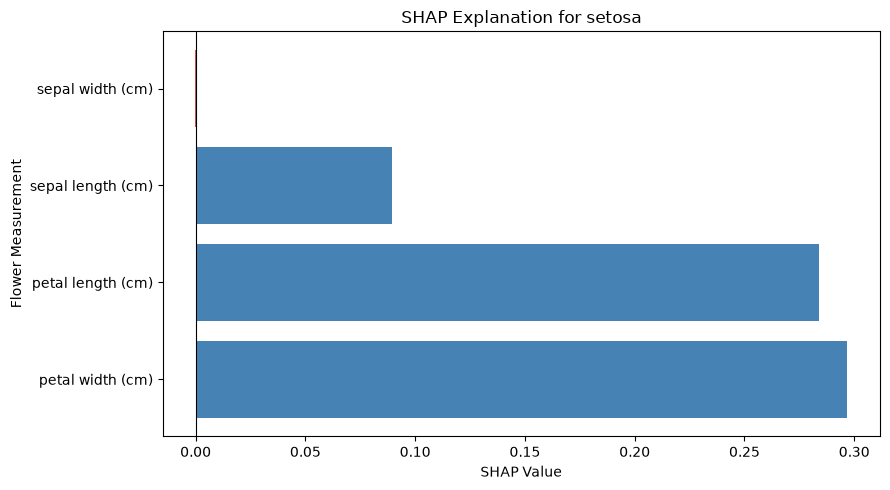


SHAP interpretation:
- Larger absolute SHAP values indicate stronger contributions.
- Positive and negative values are relative to the
- selected class's model output.
- SHAP values explain the model; they do not prove causation


In [ ]:
print("\n" + "=" * 65)
print("SHAP EXPLAINABILITY")
print("=" * 65)

print("\nCalculating SHAP Values")

try:
    shap_explainer = shap.TreeExplainer(model)
    shap_result = shap_explainer(X_test)
    shap_values = np.asarray(shap_result.values)
    

    if shap_values.ndim == 3:
        global_importance = np.abs(shap_values).mean(axis=(0,2))
        
        sample_shap = shap_values[
            sample_index,
            :,
            predicted_class
        ]

    elif shap_values.ndim == 2:
        global_importance = np.abs(shap_values).mean(axis=0)
        sample_shap = shap_values[sample_index]

    else:
        raise ValueError(
            f"Unexpected SHAP Output shape: {shap_values.shape}"
        )
    
    shap_importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Mean Absolute SHAP Value": global_importance
    }).sort_values(
        by="Mean Absolute SHAP Value",
        ascending=False
    )

    print("\nGlobal SHAP feature importance:")

    print(shap_importance_df.to_string(
        index=False,
        formatters={"Mean Absolute SHAP Value": "{:.5f}".format}
    ))
    
    # Second Graph

    plt.figure(figsize=(9,5))
    
    plt.barh(
            shap_importance_df["Feature"],
            shap_importance_df["Mean Absolute SHAP Value"]
    )
    
    plt.xlabel("Mean Absolute SHAP Value")
    plt.ylabel("Flower Measurement")
    plt.title("SHAP Global Feature Importance")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

    local_shap_df = pd.DataFrame({
        "Feature": feature_names,
        "Measurement (cm)": sample[0],
        "SHAP Value": sample_shap
    })

    local_shap_df["Absolute SHAP"] = (
        local_shap_df["SHAP Value"].abs()
    )

    local_shap_df = local_shap_df.sort_values(
        by = "Absolute SHAP",
        ascending=False
    )

    print("\n SHAP Explanation for the sample prediction:")

    print(local_shap_df[
        ["Feature", "Measurement (cm)", "SHAP Value"]
    ].to_string(
        index=False,
        formatters={
            "Measurement (cm)": "{:.2f}".format,
            "SHAP Value":  "{:.5f}".format
        }
    ))

    # Third Graph

    plt.figure(figsize=(9,5))

    bar_colors=[
        "steelblue" if value >=0 else "indianred"
        for value in local_shap_df["SHAP Value"]
    ]

    plt.barh(
        local_shap_df["Feature"],
        local_shap_df["SHAP Value"],
        color=bar_colors
    )

    plt.axvline(0, color="black", linewidth=0.8)
    plt.xlabel("SHAP Value")
    plt.ylabel("Flower Measurement")
    plt.title(f"SHAP Explanation for {predicted_species}")
    plt.tight_layout()
    plt.show()

    print("\nSHAP interpretation:")
    print("- Larger absolute SHAP values indicate stronger contributions.")
    print("- Positive and negative values are relative to the")
    print("- selected class's model output.")
    print("- SHAP values explain the model; they do not prove causation")


except Exception as error:
    print("\n SHAP explanation could not be completed.")
    print(f"Reason: {error}")
    print("Check that the SHAP and Numpy versions are compatible")


LIME EXPLAINABILITY

LIME Explanation for the selected flower:
petal length (cm) <= 1.60: 0.43446
petal width (cm) <= 0.30: 0.43351
sepal length (cm) <= 5.10: 0.02950
2.80 < sepal width (cm) <= 3.00: -0.00547


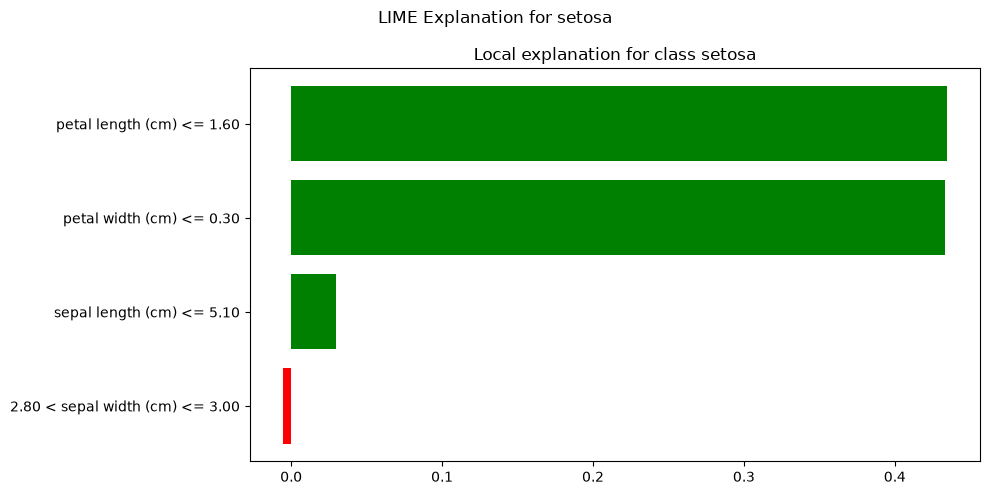


 LIME Interpretation:
- LIME Approximates the model around 1 selected sample.
- Positive contributions support the explained class.
- Negative contributions oppose that class locally.


In [8]:
print("\n" + "=" * 65)
print("LIME EXPLAINABILITY")
print("=" * 65)

lime_explainer = None

try:
    lime_explainer = LimeTabularExplainer(
        training_data=X_train,
        feature_names=feature_names,
        class_names=class_names,
        mode="classification",
        discretize_continuous=True,
        random_state=42
    )

    lime_explanation = lime_explainer.explain_instance(
        data_row=sample[0],
        predict_fn=model.predict_proba,
        labels=(predicted_class,),
        num_features=len(feature_names),
        num_samples=3000
    )

    print("\nLIME Explanation for the selected flower:")

    lime_results = lime_explanation.as_list(
        label=predicted_class
    )

    for rule, contribution in lime_results:
        print(f"{rule}: {contribution:.5f}")

    figure = lime_explanation.as_pyplot_figure(
        label=predicted_class
    )

    figure.set_size_inches(10,5)
    figure.suptitle(
        f"LIME Explanation for {predicted_species}"
    )

    plt.tight_layout()
    plt.show()

    print("\n LIME Interpretation:")
    print("- LIME Approximates the model around 1 selected sample.")
    print("- Positive contributions support the explained class.")
    print("- Negative contributions oppose that class locally.")

except Exception as error:
    print("\nLIME explanation could not be completed")
    print(f"Reason: {error}")

In [9]:
import sys
print(sys.executable)
print(sys.version)

c:\Users\cgqua\Downloads\KevsAndEricka\mlops_deployment\ai_engineering_portfolio\.venv314\Scripts\python.exe
3.14.10 (tags/v3.14.10:b703b2c, Oct 25 2026, 17:36:52) [MSC v.1944 64 bit (AMD64)]



CUSTOM IRIS FLOWER PREDICTION

Enter Flower Measurement in Centimeters.
Expected ranges are approximately:
Sepal Length: 4.3 to 7.9:
Sepal Width: 2.0 to 4.4:
Petal Length: 1.0 to 6.9:
Petal Width: 0.1 to 2.5:

Prediction Result:
Predicted Species: virginica

Prediction Probabilities:
setosa: 0.00%
versicolor: 27.00%
virginica: 73.00%

CUSTOM IRIS PREDICTION
Predicted species:  virginica

Prediction Probabilities:
setosa:0.00%
versicolor:27.00%
virginica:73.00%

Generating LIME Explanation


LIME Explantion for your flower:
petal width (cm) > 1.80: 0.41368
1.60 < petal length (cm) <= 4.25: -0.13254
sepal length (cm) <= 5.10: 0.04538
sepal width (cm) <= 2.80: 0.00587


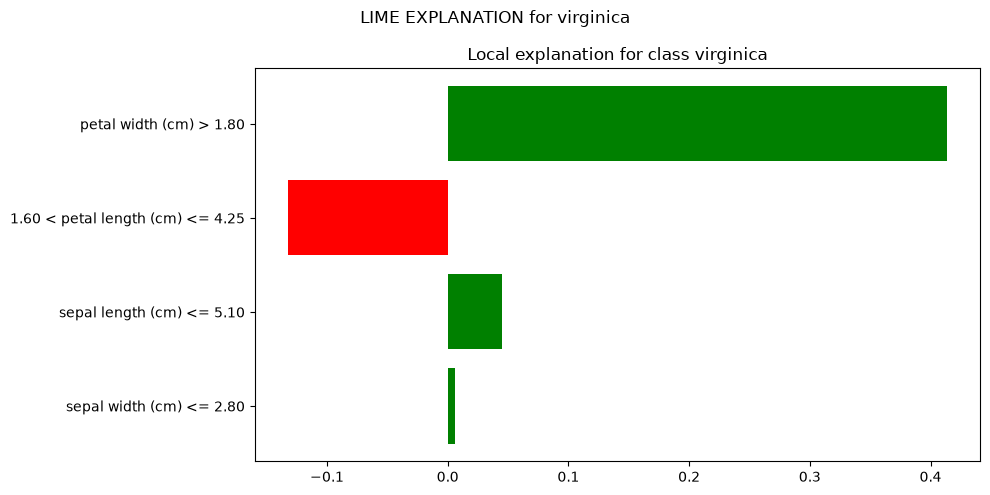


LIME Interpretation:
- Positive contributions support the explained class locally.
- Negative contributions oppose the explained class locally.
- LIME explains the model's local behavior; it does not provide causation

Program Completed. Thank you!

End of XAI Iris Projects


In [10]:
print("\n" + "=" * 65)
print("CUSTOM IRIS FLOWER PREDICTION")
print("=" * 65)

print("\nEnter Flower Measurement in Centimeters.")
print("Expected ranges are approximately:")
print("Sepal Length: 4.3 to 7.9:")
print("Sepal Width: 2.0 to 4.4:")
print("Petal Length: 1.0 to 6.9:")
print("Petal Width: 0.1 to 2.5:")

while True:
    choice = input(
        "\nWould you like to predict your own flower? (y/n)"
    ).strip().lower()

    if choice == "n":
        print("\nProgram Completed. Thank you!")
        break

    if choice != "y":
        print("Please enter y or n.")
        continue

    try:
        measurements = []

        for feature in feature_names:
            value = float(
                input(f"Enter {feature} in cm: ")
            )

            if not np.isfinite(value):
                raise ValueError(
                    "Measurements must be finite numbers."
                )

            if value <=0 :
                raise ValueError(
                    "Measurements must be greater than zero."
                )

            measurements.append(value)

        new_flower = np.array(
            measurements,
            dtype=float
        ).reshape(1,-1)

        new_prediction = int(model.predict(new_flower)[0])

        new_probabilities = model.predict_proba(new_flower)[0]

        print("\nPrediction Result:")
        print(f"Predicted Species: {class_names[new_prediction]}")

        print("\nPrediction Probabilities:")

        for species, probability in zip(
            class_names,
            new_probabilities
        ):

            print(f"{species}: {probability:.2%}")

        if lime_explainer is not None:
            try:
                custom_input = np.asarray(
                    new_flower,
                    dtype=float
                ).reshape(1,len(feature_names))

                #custom_prediction = int(
                    #model.predict(custom_input)[0]
                #)

                #custom_probabilities = model.predict_proba(
                    #model.predict(custom_input)
                #)[0]

                print("\n" + "=" * 65)
                print("CUSTOM IRIS PREDICTION")
                print("=" * 65)


                print(
                    f"Predicted species: "
                    f" {class_names[new_prediction]}"
                )

                print("\nPrediction Probabilities:")

                for class_index, probability in enumerate(
                    new_probabilities
                ):

                    print(
                        f"{class_names[class_index]}:"
                        f"{probability:.2%}"
                    )

                print("\nGenerating LIME Explanation")

                new_explanation = lime_explainer.explain_instance(

                    data_row = custom_input[0],
                    predict_fn=model.predict_proba,
                    labels=(new_prediction,),
                    num_features=len(feature_names),
                    num_samples=1000
                )

                print("\n" + "=" * 65)
                print("\nLIME Explantion for your flower:")
                print("=" * 65)

                lime_results = new_explanation.as_list(
                    label=new_prediction
                )

                for rule, contribution in lime_results:
                    print(f"{rule}: {contribution:.5f}")

                new_figure = new_explanation.as_pyplot_figure(
                    label=new_prediction
                )

                new_figure.set_size_inches(10, 5)

                new_figure.suptitle(
                    f"LIME EXPLANATION for "
                    f"{class_names[new_prediction]}"
                )

                new_figure.tight_layout()
                plt.show()
                plt.close(new_figure)

                print("\nLIME Interpretation:")
                print(
                    "- Positive contributions support the "
                    "explained class locally."
                )
                print(
                    "- Negative contributions oppose the "
                    "explained class locally."
                )
                print(
                    "- LIME explains the model's local behavior; "
                    "it does not provide causation"
                )

            except Exception as error:
                print("\nLIME Explanation failed!")
                print(
                    f"Error type: {type(error).__name__}"
                )
                print(f"Error details: {error}")

                #Print the full traceback to help diagnose
                #the exact line causing the failure
                traceback.print_exc()

        else:
            print(
                "\nLIME Explainer is unavailable. "
                "The flower prediction was completed, "
                "but its LIME Explanation cannot be generated."

            )

    except ValueError as error:
        print(f"\nInvalid input: {error}")
        print("Please try again with valid numeric measurements")

    except Exception as error:
        print(f"\nPrediction failed: {error}")

print("\nEnd of XAI Iris Projects")